In [ ]:
import tensorflow as tf

print("GPU Available:", tf.config.list_physical_devices('GPU'))


GPU Available: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


In [ ]:
!nvidia-smi

Sun Nov  1 09:06:11 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.82.07              Driver Version: 580.82.07      CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000000:00:04.0 Off |                    0 |
| N/A   42C    P8             10W /   70W |       3MiB /  15360MiB |      0%      Default |
|                                         |                        |                  N/A |
+-----------------------------------------+-----

In [ ]:
from google.colab import drive
drive.mount('/content/drive')


Mounted at /content/drive


In [ ]:

import os

print(os.listdir('/content/drive/MyDrive'))


['Colab Notebooks', 'Fast-Dreambooth', 'IMG-20260316-WA0087.jpg', 'IMG-20260316-WA0043.jpg', 'IMG-20260316-WA0012.jpg', 'IMG-20260316-WA0006.jpg', 'IMG-20260316-WA0074.jpg', 'IMG-20260316-WA0040.jpg', 'IMG-20260316-WA0032.jpg', 'IMG-20260316-WA0020.jpg', 'IMG-20260316-WA0080.jpg', 'IMG-20260316-WA0095.jpg', 'IMG-20260316-WA0064.jpg', 'IMG-20260316-WA0035.jpg', 'IMG-20260316-WA0024.jpg', 'IMG-20260316-WA0066.jpg', 'IMG-20260316-WA0077.jpg', 'IMG-20260316-WA0028.jpg', 'IMG-20260316-WA0009.jpg', 'IMG-20260316-WA0050.jpg', 'IMG-20260316-WA0051.jpg', 'IMG-20260316-WA0017.jpg', 'IMG-20260316-WA0037.jpg', 'IMG-20260316-WA0055.jpg', 'IMG-20260316-WA0013.jpg', 'IMG-20260316-WA0058.jpg', 'IMG-20260316-WA0078.jpg', 'IMG-20260316-WA0015.jpg', 'IMG-20260316-WA0042.jpg', 'IMG-20260316-WA0075.jpg', 'IMG-20260316-WA0049.jpg', 'IMG-20260316-WA0001.jpg', 'IMG-20260316-WA0025.jpg', 'IMG-20260316-WA0023.jpg', 'IMG-20260316-WA0011.jpg', 'IMG-20260316-WA0029.jpg', 'IMG-20260316-WA0008.jpg', 'IMG-20260316-WA

In [ ]:

import os

for root, dirs, files in os.walk('/content/drive/MyDrive'):
    for file in files:
        if 'brain_tumor_detection' in file.lower():
            print("FOUND:", os.path.join(root, file))


FOUND: /content/drive/MyDrive/Colab Notebooks/brain_tumor_detection.ipynb
FOUND: /content/drive/MyDrive/brain tumor project/brain_tumor_detection.zip


In [ ]:

import zipfile
import os

zip_path = '/content/drive/MyDrive/brain tumor project/brain_tumor_detection.zip'

extract_path = '/content/brain_tumor_data'

with zipfile.ZipFile(zip_path, 'r') as zip_ref:
    zip_ref.extractall(extract_path)

print("Dataset extracted successfully!")


Dataset extracted successfully!


In [ ]:

import os

for root, dirs, files in os.walk('/content/brain_tumor_data'):
    if files:
        print(root, ":", len(files), "images")


/content/brain_tumor_data/Training/notumor : 1400 images
/content/brain_tumor_data/Training/pituitary : 1400 images
/content/brain_tumor_data/Training/meningioma : 1400 images
/content/brain_tumor_data/Training/glioma : 1400 images
/content/brain_tumor_data/Testing/notumor : 400 images
/content/brain_tumor_data/Testing/pituitary : 400 images
/content/brain_tumor_data/Testing/meningioma : 400 images
/content/brain_tumor_data/Testing/glioma : 400 images


In [ ]:

import os

dataset_path = '/content/brain_tumor_data'

print(os.listdir(dataset_path))


['Training', 'Testing']


In [ ]:

import os

for split in ['Training', 'Testing']:
    split_path = os.path.join(dataset_path, split)

    print("\n", split)

    for category in os.listdir(split_path):
        category_path = os.path.join(split_path, category)

        if os.path.isdir(category_path):
            count = len(os.listdir(category_path))
            print(category, ":", count, "images")



 Training
notumor : 1400 images
pituitary : 1400 images
meningioma : 1400 images
glioma : 1400 images

 Testing
notumor : 400 images
pituitary : 400 images
meningioma : 400 images
glioma : 400 images


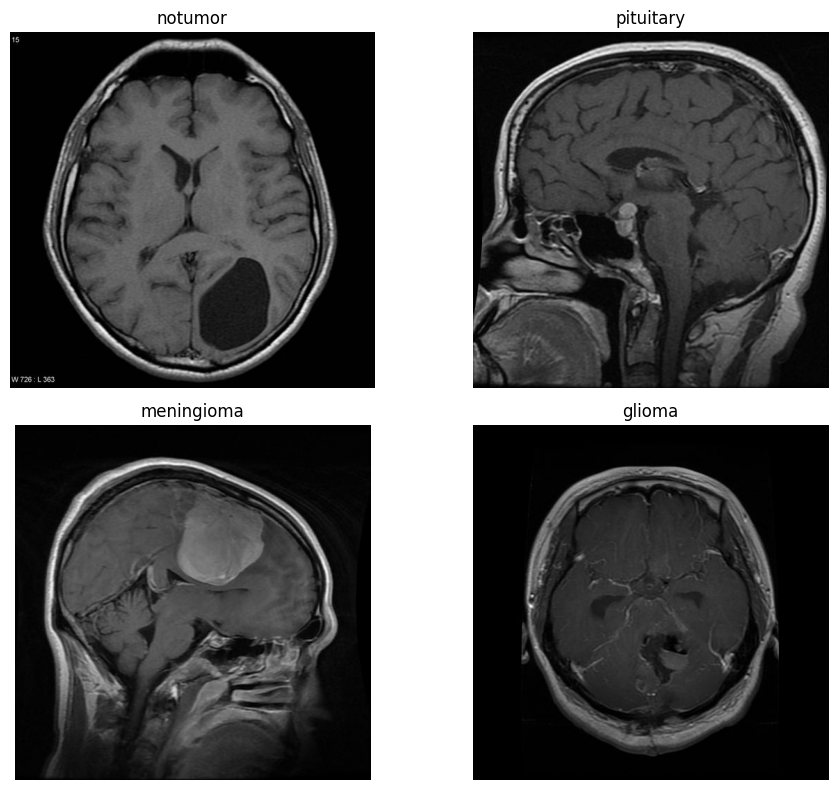

In [ ]:

import matplotlib.pyplot as plt
import os
from PIL import Image

training_path = '/content/brain_tumor_data/Training'

categories = os.listdir(training_path)

plt.figure(figsize=(10, 8))

for i, category in enumerate(categories[:4]):
    folder = os.path.join(training_path, category)

    images = os.listdir(folder)

    img = Image.open(os.path.join(folder, images[0]))

    plt.subplot(2, 2, i + 1)
    plt.imshow(img, cmap='gray')
    plt.title(category)
    plt.axis('off')

plt.tight_layout()
plt.show()


In [ ]:

import tensorflow as tf

IMG_SIZE = 224
BATCH_SIZE = 32

train_data = tf.keras.utils.image_dataset_from_directory(
    '/content/brain_tumor_data/Training',
    image_size=(IMG_SIZE, IMG_SIZE),
    batch_size=BATCH_SIZE,
    label_mode='categorical'
)

test_data = tf.keras.utils.image_dataset_from_directory(
    '/content/brain_tumor_data/Testing',
    image_size=(IMG_SIZE, IMG_SIZE),
    batch_size=BATCH_SIZE,
    label_mode='categorical',
    shuffle=False
)

print("Training and testing datasets loaded successfully!")


Found 5600 files belonging to 4 classes.
Found 1600 files belonging to 4 classes.
Training and testing datasets loaded successfully!


In [ ]:

normalization_layer = tf.keras.layers.Rescaling(1./255)

train_data = train_data.map(
    lambda x, y: (normalization_layer(x), y)
)

test_data = test_data.map(
    lambda x, y: (normalization_layer(x), y)
)

print("Image normalization completed successfully!")


Image normalization completed successfully!


In [ ]:

from tensorflow.keras import layers, models

model = models.Sequential([

    layers.Input(shape=(224, 224, 3)),

    layers.Conv2D(32, (3,3), activation='relu'),
    layers.MaxPooling2D(2,2),

    layers.Conv2D(64, (3,3), activation='relu'),
    layers.MaxPooling2D(2,2),

    layers.Conv2D(128, (3,3), activation='relu'),
    layers.MaxPooling2D(2,2),

    layers.Flatten(),

    layers.Dense(128, activation='relu'),
    layers.Dropout(0.5),

    layers.Dense(4, activation='softmax')
])

print("CNN model created successfully!")


CNN model created successfully!


In [ ]:

model.compile(
    optimizer='adam',
    loss='categorical_crossentropy',
    metrics=['accuracy']
)

print("CNN model compiled successfully!")


CNN model compiled successfully!


In [ ]:
history = model.fit(
    train_data,
    validation_data=test_data,
    epochs=20
)

Epoch 1/20
175/175 ━━━━━━━━━━━━━━━━━━━━ 12s 71ms/step - accuracy: 0.9446 - loss: 0.1481 - val_accuracy: 0.8706 - val_loss: 1.1199
Epoch 2/20
175/175 ━━━━━━━━━━━━━━━━━━━━ 12s 69ms/step - accuracy: 0.9484 - loss: 0.1379 - val_accuracy: 0.8869 - val_loss: 1.0062
Epoch 3/20
175/175 ━━━━━━━━━━━━━━━━━━━━ 21s 69ms/step - accuracy: 0.9548 - loss: 0.1179 - val_accuracy: 0.8819 - val_loss: 1.1353
Epoch 4/20
175/175 ━━━━━━━━━━━━━━━━━━━━ 12s 69ms/step - accuracy: 0.9491 - loss: 0.1420 - val_accuracy: 0.8894 - val_loss: 0.9713
Epoch 5/20
175/175 ━━━━━━━━━━━━━━━━━━━━ 13s 72ms/step - accuracy: 0.9538 - loss: 0.1172 - val_accuracy: 0.8981 - val_loss: 1.0253
Epoch 6/20
175/175 ━━━━━━━━━━━━━━━━━━━━ 12s 71ms/step - accuracy: 0.9602 - loss: 0.1053 - val_accuracy: 0.8925 - val_loss: 1.0771
Epoch 7/20
175/175 ━━━━━━━━━━━━━━━━━━━━ 13s 72ms/step - accuracy: 0.9523 - loss: 0.1199 - val_accuracy: 0.8875 - val_loss: 1.1889
Epoch 8/20
175/175 ━━━━━━━━━━━━━━━━━━━━ 13s 72ms/step - accuracy: 0.9555 - loss: 0.1166 - 

In [ ]:
test_loss, test_accuracy = model.evaluate(test_data)

print("Test Loss:", test_loss)
print("Test Accuracy:", test_accuracy * 100, "%")

50/50 ━━━━━━━━━━━━━━━━━━━━ 2s 44ms/step - accuracy: 0.9044 - loss: 1.4627
Test Loss: 1.4627330303192139
Test Accuracy: 90.43750166893005 %


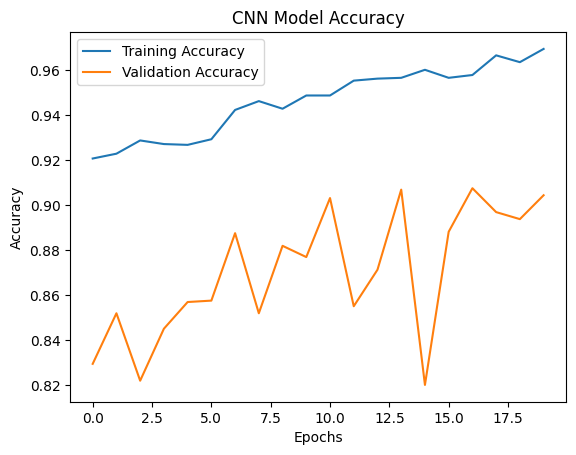

In [ ]:
import matplotlib.pyplot as plt

plt.plot(history.history['accuracy'], label='Training Accuracy')
plt.plot(history.history['val_accuracy'], label='Validation Accuracy')

plt.title('CNN Model Accuracy')
plt.xlabel('Epochs')
plt.ylabel('Accuracy')
plt.legend()
plt.show()

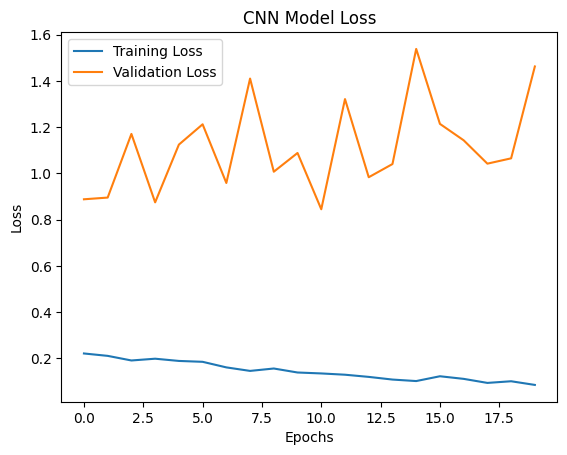

In [ ]:
plt.plot(history.history['loss'], label='Training Loss')
plt.plot(history.history['val_loss'], label='Validation Loss')

plt.title('CNN Model Loss')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.legend()
plt.show()

In [ ]:
model.save('/content/drive/MyDrive/brain tumor project/brain_tumor_cnn_model.keras')

print("Model saved successfully!")

Model saved successfully!


1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 150ms/step


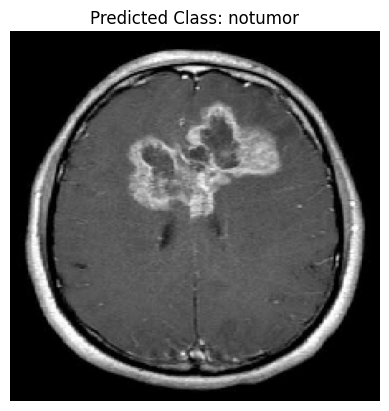

Predicted Brain MRI Class: notumor


In [ ]:
import os
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf

# Testing dataset folder
test_path = '/content/brain_tumor_data/Testing'

# Get class names in alphabetical order
class_names = sorted([
    folder for folder in os.listdir(test_path)
    if os.path.isdir(os.path.join(test_path, folder))
])

# Automatically select the first available MRI image
image_path = None

for category in class_names:
    folder_path = os.path.join(test_path, category)

    images = [
        f for f in os.listdir(folder_path)
        if f.lower().endswith(('.jpg', '.jpeg', '.png'))
    ]

    if images:
        image_path = os.path.join(folder_path, sorted(images)[0])
        break

# Load and prepare image
img = tf.keras.utils.load_img(
    image_path,
    target_size=(224, 224)
)

img_array = tf.keras.utils.img_to_array(img)
img_array = img_array / 255.0
img_array = np.expand_dims(img_array, axis=0)

# Predict tumor category
prediction = model.predict(img_array)
predicted_class = class_names[np.argmax(prediction)]

# Display result
plt.imshow(img)
plt.axis('off')
plt.title("Predicted Class: " + predicted_class)
plt.show()

print("Predicted Brain MRI Class:", predicted_class)

In [ ]:
confidence = np.max(prediction) * 100

print("Predicted Class:", predicted_class)
print("Prediction Confidence: {:.2f}%".format(confidence))

Predicted Class: notumor
Prediction Confidence: 99.96%


50/50 ━━━━━━━━━━━━━━━━━━━━ 2s 44ms/step


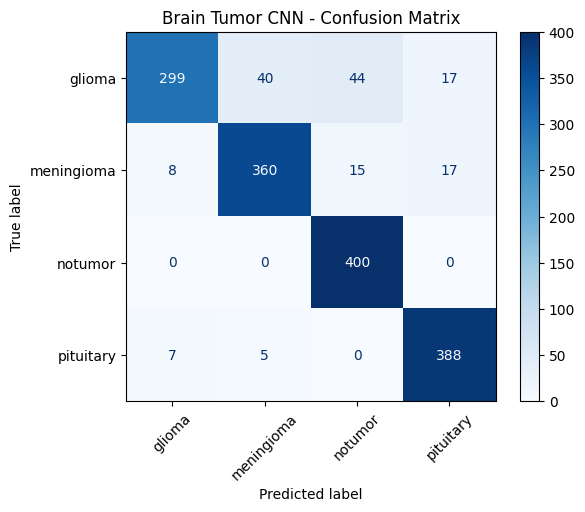

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

# Get actual labels
y_true = []

for images, labels in test_data:
    y_true.extend(np.argmax(labels.numpy(), axis=1))

# Get model predictions
predictions = model.predict(test_data)
y_pred = np.argmax(predictions, axis=1)

# Class names
class_names = sorted([
    folder for folder in os.listdir('/content/brain_tumor_data/Testing')
    if os.path.isdir(os.path.join('/content/brain_tumor_data/Testing', folder))
])

# Create confusion matrix
cm = confusion_matrix(y_true, y_pred)

# Display confusion matrix
display = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=class_names
)

display.plot(cmap='Blues', xticks_rotation=45)
plt.title('Brain Tumor CNN - Confusion Matrix')
plt.show()

In [ ]:
from sklearn.metrics import classification_report

report = classification_report(
    y_true,
    y_pred,
    target_names=class_names
)

print("BRAIN TUMOR CLASSIFICATION REPORT")
print(report)

BRAIN TUMOR CLASSIFICATION REPORT
              precision    recall  f1-score   support

      glioma       0.95      0.75      0.84       400
  meningioma       0.89      0.90      0.89       400
     notumor       0.87      1.00      0.93       400
   pituitary       0.92      0.97      0.94       400

    accuracy                           0.90      1600
   macro avg       0.91      0.90      0.90      1600
weighted avg       0.91      0.90      0.90      1600



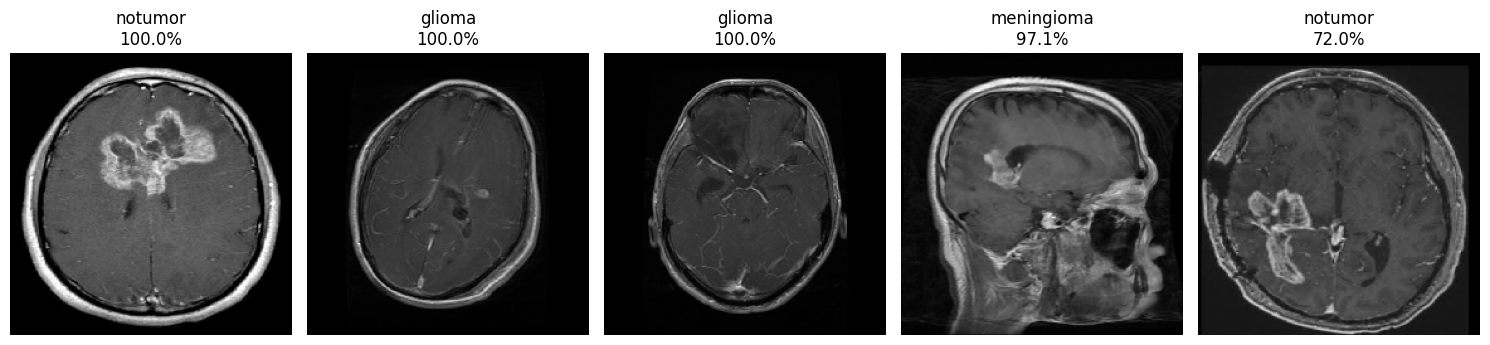

In [ ]:
import os
import numpy as np
import tensorflow as tf
import matplotlib.pyplot as plt

test_path = '/content/brain_tumor_data/Testing'

class_names = sorted([
    folder for folder in os.listdir(test_path)
    if os.path.isdir(os.path.join(test_path, folder))
])

image_paths = []

for category in class_names:
    folder_path = os.path.join(test_path, category)

    for file in sorted(os.listdir(folder_path)):
        if file.lower().endswith(('.jpg', '.jpeg', '.png')):
            image_paths.append(os.path.join(folder_path, file))

        if len(image_paths) == 5:
            break

    if len(image_paths) == 5:
        break

plt.figure(figsize=(15, 8))

for i, path in enumerate(image_paths):
    img = tf.keras.utils.load_img(path, target_size=(224, 224))
    arr = tf.keras.utils.img_to_array(img) / 255.0
    arr = np.expand_dims(arr, axis=0)

    pred = model.predict(arr, verbose=0)
    predicted_class = class_names[np.argmax(pred)]
    confidence = np.max(pred) * 100

    plt.subplot(1, 5, i + 1)
    plt.imshow(img)
    plt.title(f"{predicted_class}\n{confidence:.1f}%")
    plt.axis('off')

plt.tight_layout()
plt.show()

In [ ]:
from tensorflow.keras import layers, models

# Data augmentation
data_augmentation = models.Sequential([
    layers.RandomRotation(0.05),
    layers.RandomZoom(0.1)
])

# Build improved CNN
model = models.Sequential([
    layers.Input(shape=(224, 224, 3)),
    data_augmentation,

    layers.Conv2D(32, (3, 3), activation='relu'),
    layers.MaxPooling2D(2, 2),

    layers.Conv2D(64, (3, 3), activation='relu'),
    layers.MaxPooling2D(2, 2),

    layers.Conv2D(128, (3, 3), activation='relu'),
    layers.MaxPooling2D(2, 2),

    layers.Flatten(),
    layers.Dense(128, activation='relu'),
    layers.Dropout(0.5),
    layers.Dense(4, activation='softmax')
])

# Compile model
model.compile(
    optimizer='adam',
    loss='categorical_crossentropy',
    metrics=['accuracy']
)

# Train improved model
history = model.fit(
    train_data,
    validation_data=test_data,
    epochs=20
)

Epoch 1/20
175/175 ━━━━━━━━━━━━━━━━━━━━ 15s 75ms/step - accuracy: 0.6166 - loss: 0.9202 - val_accuracy: 0.6025 - val_loss: 1.3126
Epoch 2/20
175/175 ━━━━━━━━━━━━━━━━━━━━ 13s 75ms/step - accuracy: 0.7532 - loss: 0.6202 - val_accuracy: 0.6837 - val_loss: 1.1792
Epoch 3/20
175/175 ━━━━━━━━━━━━━━━━━━━━ 20s 72ms/step - accuracy: 0.7829 - loss: 0.5442 - val_accuracy: 0.7106 - val_loss: 1.2482
Epoch 4/20
175/175 ━━━━━━━━━━━━━━━━━━━━ 13s 75ms/step - accuracy: 0.8123 - loss: 0.4821 - val_accuracy: 0.7425 - val_loss: 0.9447
Epoch 5/20
175/175 ━━━━━━━━━━━━━━━━━━━━ 13s 73ms/step - accuracy: 0.8320 - loss: 0.4358 - val_accuracy: 0.7200 - val_loss: 1.0984
Epoch 6/20
175/175 ━━━━━━━━━━━━━━━━━━━━ 12s 71ms/step - accuracy: 0.8514 - loss: 0.3824 - val_accuracy: 0.7937 - val_loss: 0.9481
Epoch 7/20
175/175 ━━━━━━━━━━━━━━━━━━━━ 12s 70ms/step - accuracy: 0.8648 - loss: 0.3511 - val_accuracy: 0.7937 - val_loss: 0.8724
Epoch 8/20
175/175 ━━━━━━━━━━━━━━━━━━━━ 13s 74ms/step - accuracy: 0.8746 - loss: 0.3180 - 

In [ ]:
model.save(
    '/content/drive/MyDrive/brain tumor project/improved_brain_tumor_cnn.keras'
)

print("Improved CNN model saved successfully!")

Improved CNN model saved successfully!
